# Actividad evaluativa 3: Modelado supervisado básico e interpretación de desempeño

**Asignatura:** Ciencia de Datos II
**Autor:** Jairo Alonso Osorio Cruz
**Programa:** Ingeniería de Software, semestre VI, Universidad de Cartagena

En la Actividad 2 preparé el dataset público *Casos positivos de COVID-19 en Colombia* del Instituto Nacional de Salud, publicado en Datos Abiertos Colombia y filtrado a los registros de Bolívar y del distrito de Cartagena. En esta actividad parto de ese archivo depurado para construir un modelo supervisado básico.

**Problemática que trabajo:** cuando a una persona se le diagnostica COVID-19, las secretarías de salud tienen que hacerle seguimiento hasta que se recupera. Algunos casos tardan mucho más que la mayoría en cerrarse como recuperados, y eso ocupa capacidad de seguimiento por más tiempo. Me interesa saber si, con la información disponible en el momento del diagnóstico, un modelo sencillo puede señalar qué casos tienen más probabilidad de tener una recuperación prolongada, es decir, de más de 21 días.

El notebook sigue el mismo orden de las instrucciones del enunciado. Todas las cifras que aparecen salen de ejecutar el código sobre el archivo real.

## 0. Configuración del entorno

Cargo las librerías y fijo una semilla aleatoria. La semilla es un número fijo que hace que la división de datos y los modelos den siempre el mismo resultado al volver a ejecutar el notebook, lo que lo hace reproducible.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEMILLA = 42

# El notebook vive en notebooks/, los datos en data/ y las figuras se guardan en figuras/
BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RUTA_DATOS = BASE / 'data' / 'covid19_bolivar_cartagena_preparado.csv'
RUTA_FIGURAS = BASE / 'figuras'
RUTA_FIGURAS.mkdir(exist_ok=True)

# Estilo sobrio para todas las gráficas
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': GRIS, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.grid': True, 'grid.color': '#e6e5df',
    'grid.linewidth': 0.6, 'axes.axisbelow': True,
})

print('Python', sys.version.split()[0])
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.5
pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Revisión del dataset preparado y definición de la variable objetivo

Cargo el CSV que dejé listo en la Actividad 2 y reviso su tamaño y sus columnas.

In [2]:
df = pd.read_csv(RUTA_DATOS)
print('Filas y columnas:', df.shape)
df.info()

Filas y columnas: (203862, 33)
<class 'pandas.DataFrame'>
RangeIndex: 203862 entries, 0 to 203861
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   fecha_reporte_web                203862 non-null  str    
 1   id_de_caso                       203862 non-null  int64  
 2   fecha_notificacion               203862 non-null  str    
 3   departamento_cod_divipola        203862 non-null  int64  
 4   departamento_nom                 203862 non-null  str    
 5   municipio_cod_divipola           203862 non-null  int64  
 6   municipio_nom                    203862 non-null  str    
 7   edad                             203862 non-null  int64  
 8   unidad_medida                    203862 non-null  int64  
 9   sexo                             203862 non-null  str    
 10  ubicacion                        203862 non-null  str    
 11  estado                           203862 non-n

De las columnas disponibles revisé tres candidatas a variable objetivo: el fallecimiento, la recuperación prolongada y los días entre síntomas y diagnóstico. Elegí `recuperacion_prolongada`, que en la Actividad 2 definí como verdadera cuando pasan más de 21 días entre el diagnóstico y la recuperación. El umbral de 21 días viene del criterio de recuperación por tiempo clínico del INS.

Antes de usarla reviso un detalle importante. Esa columna se calculó comparando `dias_diagnostico_a_recuperacion > 21` sobre todo el dataset, y cuando los días están vacíos la comparación da `False`. Por eso los casos activos y la mayoría de los fallecidos aparecen marcados como "no prolongada", aunque nunca se recuperaron. Además, algunos fallecidos tienen fecha de recuperación registrada y un pequeño grupo de ellos aparece como "prolongada". En la tabla siguiente se ve cuántos casos hay en cada situación.

In [3]:
print(pd.crosstab(df['recuperado'].fillna('Activo (vacío)'), df['recuperacion_prolongada'], margins=True))
print()
print('Recuperados sin días de diagnóstico a recuperación:',
      int((df['recuperado'].eq('Recuperado') & df['dias_diagnostico_a_recuperacion'].isna()).sum()))
print('Fallecidos con fecha de recuperación registrada:',
      int((df['recuperado'].eq('Fallecido') & df['fecha_recuperado'].notna()).sum()))

recuperacion_prolongada   False   True     All
recuperado                                    
Activo (vacío)               43      0      43
Fallecido                  4331     43    4374
Recuperado               180116  19329  199445
All                      184490  19372  203862

Recuperados sin días de diagnóstico a recuperación: 316
Fallecidos con fecha de recuperación registrada: 147


La variable objetivo solo tiene sentido para quien se recuperó, así que defino la población de estudio como los casos con `recuperado == 'Recuperado'` que además tienen calculados los días de diagnóstico a recuperación. Dejo fuera a los fallecidos, a los casos activos y a los recuperados sin fecha de diagnóstico, porque en ellos no se puede saber si la recuperación fue prolongada.

In [4]:
pob = df[df['recuperado'].eq('Recuperado') & df['dias_diagnostico_a_recuperacion'].notna()].copy()
pob['objetivo'] = (pob['dias_diagnostico_a_recuperacion'] > 21).astype(int)

# Compruebo que coincide con la columna de la Actividad 2 dentro de la población
assert (pob['objetivo'] == pob['recuperacion_prolongada'].astype(int)).all()

print('Casos en la población de estudio:', len(pob))
print('Casos excluidos:', len(df) - len(pob))
conteo = pob['objetivo'].value_counts().sort_index()
print(pd.DataFrame({'casos': conteo, 'porcentaje': (conteo / len(pob) * 100).round(2)})
      .rename(index={0: 'No prolongada (0)', 1: 'Prolongada (1)'}))

Casos en la población de estudio: 199129
Casos excluidos: 4733
                    casos  porcentaje
objetivo                             
No prolongada (0)  179800       90.29
Prolongada (1)      19329        9.71


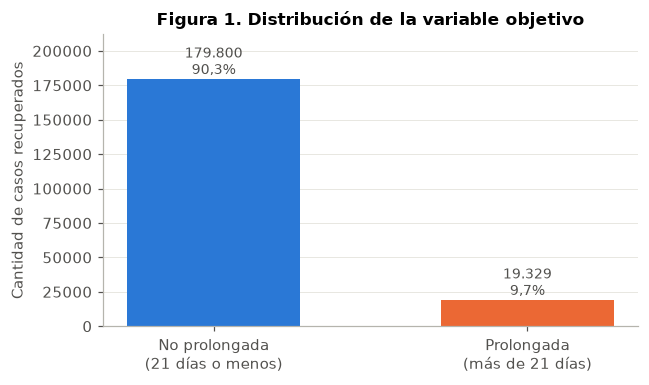

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6))
etiquetas = ['No prolongada\n(21 días o menos)', 'Prolongada\n(más de 21 días)']
barras = ax.bar(etiquetas, conteo.values, color=[AZUL, NARANJA], width=0.55)
for b, n in zip(barras, conteo.values):
    ax.annotate(f'{n:,}'.replace(',', '.') + f'\n{n / len(pob):.1%}'.replace('.', ','),
                (b.get_x() + b.get_width() / 2, n), ha='center', va='bottom', fontsize=9, color=GRIS)
ax.set_ylabel('Cantidad de casos recuperados')
ax.set_title('Figura 1. Distribución de la variable objetivo')
ax.set_ylim(0, conteo.max() * 1.18)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'fig1_distribucion_objetivo.png')
plt.show()

Miro también cómo cambia la proporción de recuperaciones prolongadas con la edad y con el año del diagnóstico. Esta exploración me sirve para saber si las variables que pienso usar tienen alguna relación con el objetivo.

Proporción de recuperación prolongada por grupo de edad:
            % prolongada  casos
edad_anios                     
0-19                8.51  24984
20-39               9.49  86015
40-59               9.67  60526
60-69              11.23  16542
70-79              12.10   7473
80+                11.79   3589

Proporción de recuperación prolongada por año de diagnóstico:
                   % prolongada   casos
fecha_diagnostico                      
2020                      18.28   52222
2021                       5.48  108422
2022                       9.77   38106
2023                      31.56     377
2024                       0.00       2


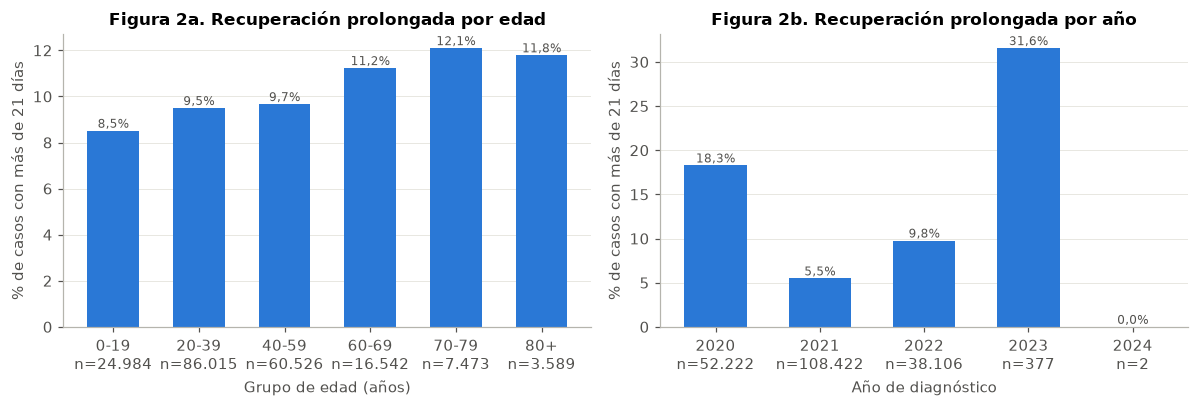

In [6]:
pob['fecha_diagnostico'] = pd.to_datetime(pob['fecha_diagnostico'])
grupos_edad = pd.cut(pob['edad_anios'], [-1, 19, 39, 59, 69, 79, 120],
                     labels=['0-19', '20-39', '40-59', '60-69', '70-79', '80+'])
por_edad = pob.groupby(grupos_edad, observed=True)['objetivo'].agg(['mean', 'size'])
por_anio = pob.groupby(pob['fecha_diagnostico'].dt.year)['objetivo'].agg(['mean', 'size'])
print('Proporción de recuperación prolongada por grupo de edad:')
print(por_edad.assign(mean=(por_edad['mean'] * 100).round(2)).rename(columns={'mean': '% prolongada', 'size': 'casos'}))
print()
print('Proporción de recuperación prolongada por año de diagnóstico:')
print(por_anio.assign(mean=(por_anio['mean'] * 100).round(2)).rename(columns={'mean': '% prolongada', 'size': 'casos'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, datos, titulo, xlabel in [
        (axes[0], por_edad, 'Figura 2a. Recuperación prolongada por edad', 'Grupo de edad (años)'),
        (axes[1], por_anio, 'Figura 2b. Recuperación prolongada por año', 'Año de diagnóstico')]:
    etiquetas_x = [f'{i}\nn={n:,}'.replace(',', '.') for i, n in zip(datos.index.astype(str), datos['size'])]
    ax.bar(etiquetas_x, datos['mean'] * 100, color=AZUL, width=0.6)
    for x, v in zip(etiquetas_x, datos['mean'] * 100):
        ax.annotate(f'{v:.1f}%'.replace('.', ','), (x, v), ha='center', va='bottom', fontsize=8, color=GRIS)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('% de casos con más de 21 días')
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'fig2_exploracion_edad_anio.png')
plt.show()

## 2. Justificación del problema como aprendizaje supervisado

El aprendizaje supervisado consiste en entrenar un modelo con ejemplos de los que ya se conoce la respuesta correcta, llamada variable objetivo o etiqueta, para que luego pueda estimar esa respuesta en casos nuevos. Este problema encaja ahí porque cada caso recuperado del dataset ya trae la etiqueta: sé si tardó más de 21 días o no.

Como la respuesta es una categoría con dos valores, sí o no, el problema es de **clasificación binaria** y no de regresión. La regresión se usaría si quisiera estimar una cantidad, por ejemplo el número exacto de días.

Lo que espero que haga el modelo es lo siguiente: a partir de datos que ya se conocen el día del diagnóstico, como la edad, el sexo, el territorio o la fecha, estimar si ese caso terminará con una recuperación prolongada. La clase positiva, que marco con 1, es "recuperación prolongada".

## 3. Selección de variables predictoras y variables excluidas

Para escoger los predictores me hice una pregunta para cada columna: ¿este dato ya se conoce el día del diagnóstico? Si solo se conoce después, cuando el caso ya se cerró, usarlo sería **fuga de información**. La fuga de información ocurre cuando el modelo usa datos que no tendría en la práctica y que de alguna forma contienen la respuesta. Eso infla las métricas y hace que el modelo falle al usarlo de verdad.

Primero compruebo qué valores toman `estado` y `ubicacion` dentro de la población de estudio, porque de eso depende si sirven o no.

In [7]:
print(pob['estado'].value_counts(dropna=False))
print()
print(pob['ubicacion'].value_counts(dropna=False))
print()
print('caso_activo:', pob['caso_activo'].unique(), '| alerta_muerte_antes_diagnostico:',
      pob['alerta_muerte_antes_diagnostico'].unique())

estado
Leve    199129
Name: count, dtype: int64

ubicacion
Casa    199129
Name: count, dtype: int64

caso_activo: [False] | alerta_muerte_antes_diagnostico: [False]


Con esa revisión dejo documentada la decisión sobre cada columna excluida.

In [8]:
excluidas = pd.DataFrame([
    ('id_de_caso', 'Identificador directo', 'Es un consecutivo administrativo y no describe al paciente.'),
    ('dias_diagnostico_a_recuperacion', 'Fuga de información', 'Con ella se calcula el objetivo; el modelo vería la respuesta.'),
    ('recuperacion_prolongada', 'Fuga de información', 'Es la misma variable objetivo de la Actividad 2.'),
    ('fecha_recuperado', 'Fuga de información', 'Solo se conoce al cerrar el caso y define la duración.'),
    ('tipo_recuperacion', 'Fuga de información', 'Se registra al cerrar el caso según cómo se confirmó la recuperación.'),
    ('recuperado', 'Fuga de información / constante', 'Es el desenlace del caso y vale Recuperado en toda la población.'),
    ('estado', 'Desenlace / constante', 'Es el estado final del caso y no varía dentro de la población.'),
    ('ubicacion', 'Desenlace / constante', 'Es la ubicación final del caso y no varía dentro de la población.'),
    ('estado_severidad_cod', 'Desenlace / constante', 'Es la codificación numérica de estado.'),
    ('nivel_riesgo', 'Fuga de información / redundante', 'Se construyó con estado y edad; la edad ya entra directamente.'),
    ('nivel_riesgo_cod', 'Fuga de información / redundante', 'Es la codificación numérica de nivel_riesgo.'),
    ('fecha_muerte', 'Irrelevante', 'Está vacía en toda la población porque son recuperados.'),
    ('alerta_muerte_antes_diagnostico', 'Irrelevante', 'Es constante dentro de la población.'),
    ('caso_activo', 'Irrelevante', 'Es constante dentro de la población.'),
    ('edad', 'Redundante', 'Puede venir en años, meses o días; uso edad_anios, que ya está unificada.'),
    ('unidad_medida', 'Redundante', 'Solo indica la unidad de edad, ya resuelta en edad_anios.'),
    ('edad_atipica_iqr', 'Redundante', 'Es un umbral sobre edad_anios y no agrega información nueva.'),
    ('sexo', 'Redundante', 'Uso su versión codificada sexo_cod.'),
    ('departamento_cod_divipola', 'Redundante', 'Repite departamento_nom; lo convierto en es_cartagena.'),
    ('municipio_cod_divipola, municipio_nom', 'Irrelevante para un modelo base', '46 municipios con pocos casos en la mayoría; me quedo con la distinción Cartagena o resto de Bolívar.'),
    ('fecha_reporte_web, fecha_notificacion', 'Redundante / riesgo de fuga', 'Son fechas administrativas que pueden registrarse después del diagnóstico; el tiempo ya entra con fecha_diagnostico.'),
    ('fecha_inicio_sintomas', 'Redundante', 'Su información entra en dias_sintomas_a_diagnostico.'),
    ('contagio_Comunitaria', 'Categoría de referencia', 'Las tres columnas de contagio suman 1 en cada fila; con dos basta.'),
], columns=['columna', 'motivo', 'explicación'])
pd.set_option('display.max_colwidth', 120)
excluidas

,columna,motivo,explicación
0,id_de_caso,Identificador directo,Es un consecutivo administrativo y no describe al paciente.
1,dias_diagnostico_a_recuperacion,Fuga de información,Con ella se calcula el objetivo; el modelo vería la respuesta.
2,recuperacion_prolongada,Fuga de información,Es la misma variable objetivo de la Actividad 2.
3,fecha_recuperado,Fuga de información,Solo se conoce al cerrar el caso y define la duración.
4,tipo_recuperacion,Fuga de información,Se registra al cerrar el caso según cómo se confirmó la recuperación.
5,recuperado,Fuga de información / constante,Es el desenlace del caso y vale Recuperado en toda la población.
6,estado,Desenlace / constante,Es el estado final del caso y no varía dentro de la población.
7,ubicacion,Desenlace / constante,Es la ubicación final del caso y no varía dentro de la población.
8,estado_severidad_cod,Desenlace / constante,Es la codificación numérica de estado.
9,nivel_riesgo,Fuga de información / redundante,Se construyó con estado y edad; la edad ya entra directamente.


Las variables predictoras que conservo son las que se conocen al momento del diagnóstico. Dos de ellas las construyo a partir de columnas existentes, sin agregar datos externos:

- `es_cartagena`: vale 1 si el caso pertenece al distrito de Cartagena y 0 si pertenece al resto de Bolívar.
- `meses_desde_inicio`: meses transcurridos entre marzo de 2020 y la fecha de diagnóstico. Con ella el modelo puede captar diferencias entre etapas de la pandemia.

In [9]:
pob['es_cartagena'] = pob['departamento_nom'].eq('Cartagena').astype(int)
inicio = pd.Timestamp('2020-03-01')
pob['meses_desde_inicio'] = ((pob['fecha_diagnostico'].dt.year - inicio.year) * 12
                             + (pob['fecha_diagnostico'].dt.month - inicio.month))

VARS_NUMERICAS = ['edad_anios', 'meses_desde_inicio', 'dias_sintomas_a_diagnostico']
VARS_CATEGORICAS = ['pertenencia_etnica_cod']
# contagio_Comunitaria queda como categoría de referencia (ver explicación abajo)
VARS_BINARIAS = ['sexo_cod', 'es_cartagena', 'contagio_Importado', 'contagio_Relacionado']
PREDICTORAS = VARS_NUMERICAS + VARS_CATEGORICAS + VARS_BINARIAS

# Declaro todas las categorías étnicas para que el codificador no falle si un grupo muy pequeño
# solo queda en uno de los dos conjuntos
CATEGORIAS_ETNIA = sorted(float(c) for c in pob['pertenencia_etnica_cod'].unique())
print('Categorías étnicas:', CATEGORIAS_ETNIA)

X = pob[PREDICTORAS]
y = pob['objetivo']
print('Predictoras:', PREDICTORAS)
print('Dimensión de X:', X.shape)
print()
print('Valores faltantes por predictora:')
print(X.isna().sum())

Categorías étnicas: [1.0, 2.0, 5.0, 6.0]
Predictoras: ['edad_anios', 'meses_desde_inicio', 'dias_sintomas_a_diagnostico', 'pertenencia_etnica_cod', 'sexo_cod', 'es_cartagena', 'contagio_Importado', 'contagio_Relacionado']
Dimensión de X: (199129, 8)

Valores faltantes por predictora:
edad_anios                       0
meses_desde_inicio               0
dias_sintomas_a_diagnostico    667
pertenencia_etnica_cod           0
sexo_cod                         0
es_cartagena                     0
contagio_Importado               0
contagio_Relacionado             0
dtype: int64


El tipo de contagio llegó de la Actividad 2 como tres columnas binarias, una por categoría, y en cada caso exactamente una vale 1. Si dejo las tres, cualquiera de ellas se puede deducir de las otras dos, lo que se conoce como la trampa de las variables dummy. En la regresión logística eso impide interpretar los coeficientes por separado. Por eso dejo por fuera `contagio_Comunitaria`, que es la categoría más frecuente, y la uso como **categoría de referencia**: los coeficientes de contagio importado y relacionado se leen como diferencias frente al contagio comunitario. Hago lo mismo con la pertenencia étnica, donde la referencia es el código 6, "Otro", que es el más frecuente.

`dias_sintomas_a_diagnostico` tiene valores faltantes porque los casos asintomáticos no tienen fecha de inicio de síntomas. No borro esas filas. Las relleno con la mediana del conjunto de entrenamiento y agrego una columna indicadora que avisa al modelo que el dato faltaba. Ese tratamiento va dentro del pipeline, como explico en la sección 5.

## 4. División en conjuntos de entrenamiento y prueba

Separo los datos en dos partes. El **conjunto de entrenamiento** es la parte con la que el modelo aprende. El **conjunto de prueba** se guarda aparte y solo se usa al final para medir qué tan bien funciona el modelo con casos que nunca vio.

- Proporción: 80 % para entrenamiento y 20 % para prueba. Hay muchos registros, así que el 20 % sigue siendo una muestra grande para evaluar.
- Semilla fija `random_state=42`, para que la división sea siempre la misma.
- División **estratificada** con `stratify=y`. Como la clase prolongada es minoritaria, la estratificación garantiza que ambos conjuntos tengan la misma proporción de casos prolongados que el total.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

resumen_split = pd.DataFrame({
    'casos': [len(y_train), len(y_test)],
    'prolongados': [int(y_train.sum()), int(y_test.sum())],
    '% prolongados': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=['Entrenamiento', 'Prueba'])
print(resumen_split)
print()
print('Casos con código étnico 2 (ROM) en entrenamiento:', int((X_train['pertenencia_etnica_cod'] == 2.0).sum()),
      '| en prueba:', int((X_test['pertenencia_etnica_cod'] == 2.0).sum()))

                casos  prolongados  % prolongados
Entrenamiento  159303        15463           9.71
Prueba          39826         3866           9.71

Casos con código étnico 2 (ROM) en entrenamiento: 0 | en prueba: 1


## 5. Entrenamiento del modelo base y modelo de referencia

Entreno tres modelos con el mismo conjunto de entrenamiento:

1. **Modelo de referencia trivial** (`DummyClassifier` con estrategia `most_frequent`). No mira las variables y siempre responde la clase más frecuente, que es "no prolongada". Sirve de punto de comparación: si un modelo real no le gana, no está aportando nada.
2. **Regresión logística**. A pesar del nombre, es un modelo de clasificación. Combina las variables con unos pesos y convierte el resultado en una probabilidad entre 0 y 1. Es el modelo base que propongo por ser simple e interpretable.
3. **Árbol de decisión básico** con profundidad máxima 4. Clasifica haciendo preguntas sucesivas del tipo "¿la edad es mayor que X?". Limito la profundidad para que siga siendo un modelo sencillo y para reducir el riesgo de sobreajuste.

El **sobreajuste** ocurre cuando el modelo memoriza el entrenamiento y le va mucho peor con datos nuevos. El **subajuste** es lo contrario: el modelo es tan simple que no capta la relación ni siquiera en el entrenamiento. Comparar las métricas de entrenamiento y de prueba me permite detectar cualquiera de los dos.

Como la clase prolongada es minoritaria, en los dos modelos reales uso `class_weight='balanced'`. Ese parámetro hace que los errores sobre la clase minoritaria pesen más durante el entrenamiento. Sin él, un modelo tiende a copiar al de referencia y a decir "no prolongada" casi siempre.

Todo el preprocesamiento va dentro de un `Pipeline` de scikit-learn. A la regresión logística le estandarizo las variables numéricas, es decir, las llevo a una escala común con media 0 y desviación 1, porque es sensible a la escala. Al árbol no se lo hago porque no lo necesita. Así, la mediana para rellenar faltantes y la escala de las variables se calculan solo con los datos de entrenamiento, y el conjunto de prueba no influye en el aprendizaje.

In [11]:
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median', add_indicator=True)),
                      ('escalar', StandardScaler())]), VARS_NUMERICAS),
    ('cat', OneHotEncoder(categories=[CATEGORIAS_ETNIA], drop=[6.0]), VARS_CATEGORICAS),
    ('bin', 'passthrough', VARS_BINARIAS),
])

# El árbol no necesita escalar las variables; sin escalado sus umbrales quedan en meses y días reales
preprocesador_arbol = ColumnTransformer([
    ('num', SimpleImputer(strategy='median', add_indicator=True), VARS_NUMERICAS),
    ('cat', OneHotEncoder(categories=[CATEGORIAS_ETNIA], drop=[6.0]), VARS_CATEGORICAS),
    ('bin', 'passthrough', VARS_BINARIAS),
])

modelos = {
    'Referencia (Dummy)': (preprocesador, DummyClassifier(strategy='most_frequent')),
    'Regresión logística': (preprocesador, LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA)),
    'Árbol de decisión (prof. 4)': (preprocesador_arbol, DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=SEMILLA)),
}

pipelines = {}
for nombre, (prep, modelo) in modelos.items():
    # clone crea una copia sin entrenar, para que cada pipeline tenga su propio preprocesador
    pipe = Pipeline([('prep', clone(prep)), ('modelo', modelo)])
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe
    print('Entrenado:', nombre)

Entrenado: Referencia (Dummy)
Entrenado: Regresión logística


Entrenado: Árbol de decisión (prof. 4)


## 6. Métricas de desempeño

Para clasificación calculo estas métricas. La clase positiva es "recuperación prolongada".

- **Accuracy** o exactitud: porcentaje de casos clasificados correctamente sobre el total.
- **Precision** o precisión: de los casos que el modelo marcó como prolongados, qué porcentaje lo era de verdad.
- **Recall** o sensibilidad: de los casos que de verdad fueron prolongados, qué porcentaje logró detectar el modelo.
- **F1**: un promedio entre precision y recall que solo es alto si ambas lo son.
- **Matriz de confusión**: tabla que cruza la clase real con la predicha y muestra cuántos aciertos y cuántos errores de cada tipo hubo.

Las calculo en entrenamiento y en prueba para revisar sobreajuste o subajuste.

In [12]:
def metricas(pipe, X_, y_):
    pred = pipe.predict(X_)
    return {'accuracy': accuracy_score(y_, pred),
            'precision': precision_score(y_, pred, zero_division=0),
            'recall': recall_score(y_, pred, zero_division=0),
            'f1': f1_score(y_, pred, zero_division=0)}

filas = []
for nombre, pipe in pipelines.items():
    for conjunto, (X_, y_) in {'Entrenamiento': (X_train, y_train), 'Prueba': (X_test, y_test)}.items():
        filas.append({'modelo': nombre, 'conjunto': conjunto, **metricas(pipe, X_, y_)})
tabla_metricas = pd.DataFrame(filas).set_index(['modelo', 'conjunto']).round(3)
tabla_metricas

accuracy  precision  recall     f1
modelo                      conjunto                                         
Referencia (Dummy)          Entrenamiento     0.903      0.000   0.000  0.000
                            Prueba            0.903      0.000   0.000  0.000
Regresión logística         Entrenamiento     0.628      0.146   0.584  0.234
                            Prueba            0.626      0.146   0.590  0.235
Árbol de decisión (prof. 4) Entrenamiento     0.818      0.279   0.549  0.370
                            Prueba            0.815      0.273   0.547  0.364

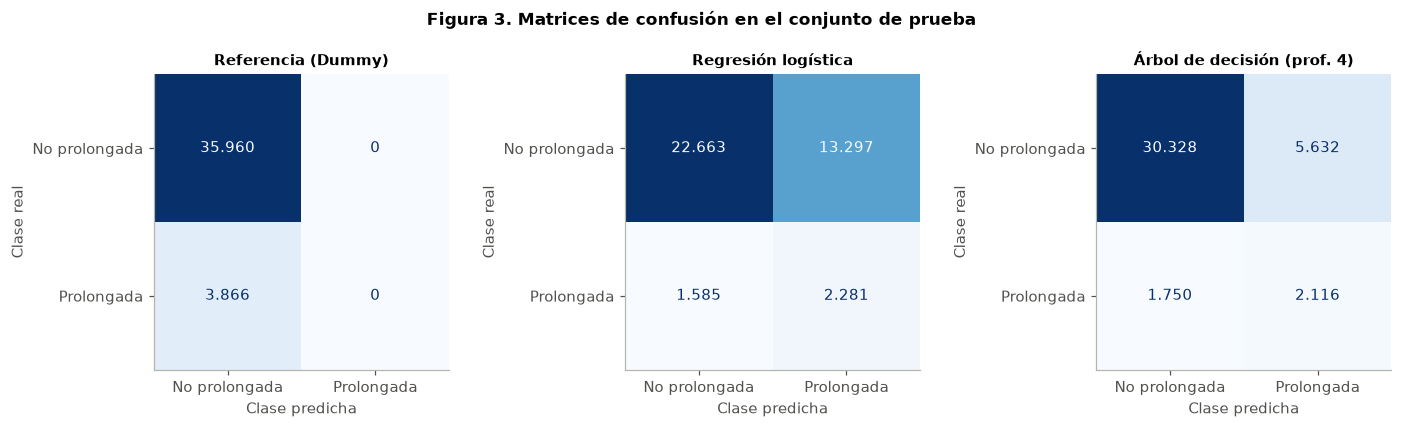

Referencia (Dummy): VN=35960, FP=0, FN=3866, VP=0, marcados como prolongados=0
Regresión logística: VN=22663, FP=13297, FN=1585, VP=2281, marcados como prolongados=15578
Árbol de decisión (prof. 4): VN=30328, FP=5632, FN=1750, VP=2116, marcados como prolongados=7748


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (nombre, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['No prolongada', 'Prolongada']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format=',d')
    for t in ax.texts:
        t.set_text(t.get_text().replace(',', '.'))
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.grid(False)
fig.suptitle('Figura 3. Matrices de confusión en el conjunto de prueba', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'fig3_matrices_confusion.png')
plt.show()

for nombre, pipe in pipelines.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
    print(f'{nombre}: VN={tn}, FP={fp}, FN={fn}, VP={tp}, marcados como prolongados={fp + tp}')

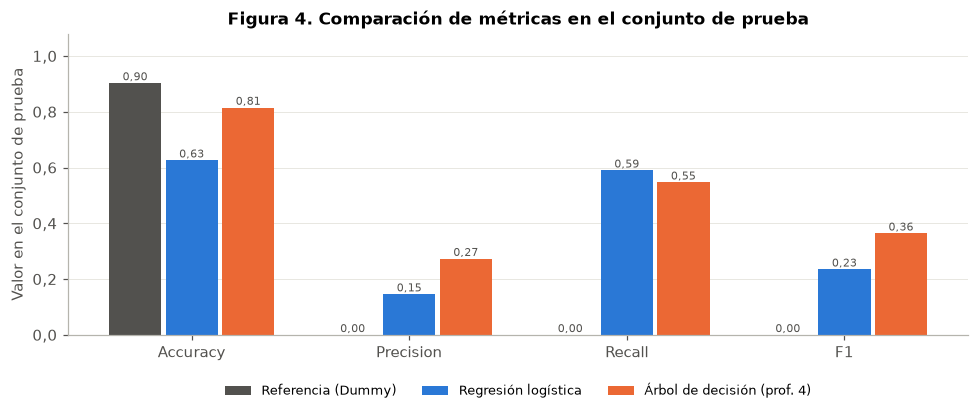

In [14]:
prueba = tabla_metricas.xs('Prueba', level='conjunto')[['accuracy', 'precision', 'recall', 'f1']]
fig, ax = plt.subplots(figsize=(9, 3.9))
x = np.arange(len(prueba.columns))
ancho = 0.26
colores = [GRIS, AZUL, NARANJA]
for i, (nombre, fila) in enumerate(prueba.iterrows()):
    ax.bar(x + (i - 1) * ancho, fila.values, ancho - 0.02, color=colores[i], label=nombre)
    for xi, v in zip(x + (i - 1) * ancho, fila.values):
        ax.annotate(f'{v:.2f}'.replace('.', ','), (xi, v), ha='center', va='bottom', fontsize=7.5, color=GRIS)
ax.set_xticks(x, ['Accuracy', 'Precision', 'Recall', 'F1'])
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ',')))
ax.set_ylabel('Valor en el conjunto de prueba')
ax.set_title('Figura 4. Comparación de métricas en el conjunto de prueba')
ax.legend(frameon=False, fontsize=8.5, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'fig4_comparacion_metricas.png')
plt.show()

Para saber si los modelos aportan algo frente a elegir casos al azar, calculo el **lift**. Es la precision del modelo dividida entre la proporción real de casos prolongados. Si elijo casos al azar, la proporción de aciertos es igual a esa prevalencia y el lift vale 1. Un lift de 2 significa que, entre los casos que marca el modelo, hay el doble de casos prolongados que en una selección al azar.

In [15]:
prevalencia = y_test.mean()
print(f'Prevalencia de recuperación prolongada en prueba: {prevalencia:.4f}')
for nombre in ['Regresión logística', 'Árbol de decisión (prof. 4)']:
    prec = tabla_metricas.loc[(nombre, 'Prueba'), 'precision']
    print(f'{nombre}: precision={prec:.3f} | lift={prec / prevalencia:.2f}')

Prevalencia de recuperación prolongada en prueba: 0.0971
Regresión logística: precision=0.146 | lift=1.50
Árbol de decisión (prof. 4): precision=0.273 | lift=2.81


Reviso el reporte completo por clase de los dos modelos reales. El `support` es la cantidad de casos reales de cada clase en el conjunto de prueba.

In [16]:
for nombre in ['Regresión logística', 'Árbol de decisión (prof. 4)']:
    print('=' * 20, nombre, '=' * 20)
    print(classification_report(y_test, pipelines[nombre].predict(X_test),
                                target_names=['No prolongada', 'Prolongada'], digits=3))

==================== Regresión logística ====================
               precision    recall  f1-score   support

No prolongada      0.935     0.630     0.753     35960
   Prolongada      0.146     0.590     0.235      3866

     accuracy                          0.626     39826
    macro avg      0.541     0.610     0.494     39826
 weighted avg      0.858     0.626     0.703     39826

==================== Árbol de decisión (prof. 4) ====================
               precision    recall  f1-score   support

No prolongada      0.945     0.843     0.892     35960
   Prolongada      0.273     0.547     0.364      3866

     accuracy                          0.815     39826
    macro avg      0.609     0.695     0.628     39826
 weighted avg      0.880     0.815     0.840     39826



Por último, miro qué variables usa cada modelo. En la regresión logística veo los coeficientes: un coeficiente positivo empuja la predicción hacia "prolongada" y uno negativo hacia "no prolongada". Las variables numéricas están estandarizadas, así que sus coeficientes se pueden comparar entre sí. Los coeficientes de etnia y de tipo de contagio se leen frente a sus categorías de referencia, "Otro" y contagio comunitario. El coeficiente del grupo ROM vale 0 porque su único caso quedó en el conjunto de prueba y el modelo no tuvo ejemplos de ese grupo para aprender. En el árbol veo la importancia de cada variable, que mide cuánto ayudó a separar las clases.

Al final muestro los dos primeros niveles del árbol, con umbrales en unidades reales, para ver qué preguntas hace primero.

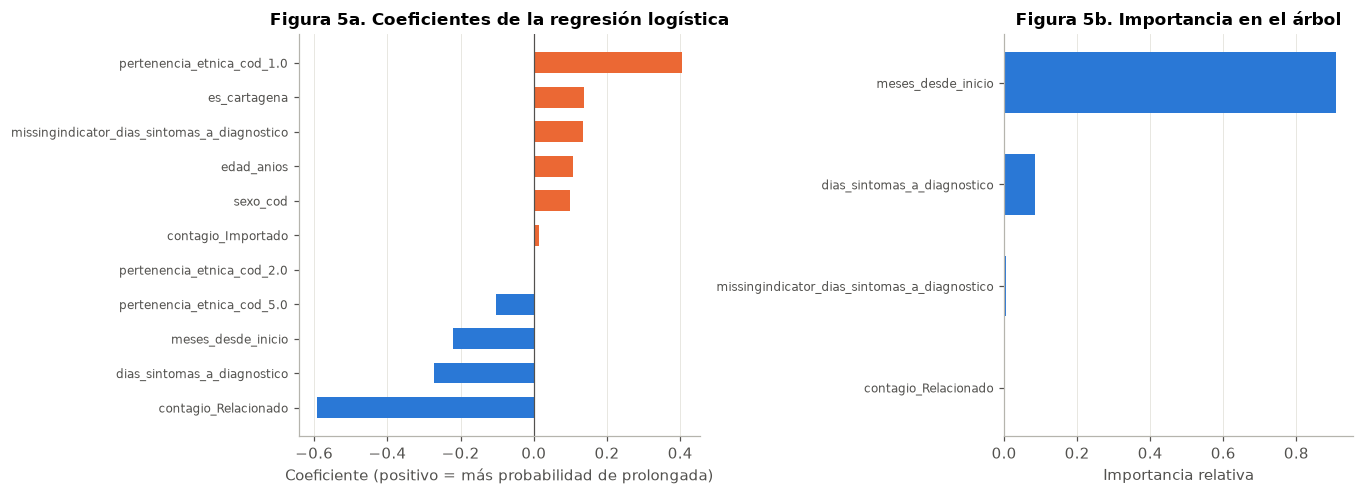

pertenencia_etnica_cod_1.0                      0.404
es_cartagena                                    0.136
missingindicator_dias_sintomas_a_diagnostico    0.135
edad_anios                                      0.108
sexo_cod                                        0.100
contagio_Importado                              0.013
pertenencia_etnica_cod_2.0                      0.000
pertenencia_etnica_cod_5.0                     -0.104
meses_desde_inicio                             -0.220
dias_sintomas_a_diagnostico                    -0.273
contagio_Relacionado                           -0.592
dtype: float64

meses_desde_inicio                              0.910
dias_sintomas_a_diagnostico                     0.084
missingindicator_dias_sintomas_a_diagnostico    0.005
contagio_Relacionado                            0.001
dtype: float64


In [17]:
def nombres_columnas(pipe):
    return [n.split('__', 1)[1] for n in pipe.named_steps['prep'].get_feature_names_out()]

nombres_log = nombres_columnas(pipelines['Regresión logística'])
nombres_arbol = nombres_columnas(pipelines['Árbol de decisión (prof. 4)'])
coef = pd.Series(pipelines['Regresión logística'].named_steps['modelo'].coef_[0], index=nombres_log).sort_values()
importancia = pd.Series(pipelines['Árbol de decisión (prof. 4)'].named_steps['modelo'].feature_importances_,
                        index=nombres_arbol).sort_values()
importancia = importancia[importancia > 0]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
axes[0].barh(coef.index, coef.values, color=[NARANJA if v > 0 else AZUL for v in coef.values], height=0.6)
axes[0].axvline(0, color=GRIS, linewidth=0.8)
axes[0].set_title('Figura 5a. Coeficientes de la regresión logística')
axes[0].tick_params(axis='y', labelsize=8)
axes[1].tick_params(axis='y', labelsize=8)
axes[0].set_xlabel('Coeficiente (positivo = más probabilidad de prolongada)')
axes[0].grid(axis='y', visible=False)
axes[1].barh(importancia.index, importancia.values, color=AZUL, height=0.6)
axes[1].set_title('Figura 5b. Importancia en el árbol')
axes[1].set_xlabel('Importancia relativa')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'fig5_variables_modelos.png')
plt.show()

print(coef.round(3).sort_values(ascending=False))
print()
print(importancia.round(3).sort_values(ascending=False))

In [18]:
arbol = pipelines['Árbol de decisión (prof. 4)'].named_steps['modelo']
print(export_text(arbol, feature_names=nombres_arbol, max_depth=2, decimals=1))

|--- meses_desde_inicio <= 4.5
|   |--- dias_sintomas_a_diagnostico <= 10.5
|   |   |--- dias_sintomas_a_diagnostico <= 8.5
|   |   |   |--- truncated branch of depth 2
|   |   |--- dias_sintomas_a_diagnostico >  8.5
|   |   |   |--- truncated branch of depth 2
|   |--- dias_sintomas_a_diagnostico >  10.5
|   |   |--- meses_desde_inicio <= 2.5
|   |   |   |--- truncated branch of depth 2
|   |   |--- meses_desde_inicio >  2.5
|   |   |   |--- truncated branch of depth 2
|--- meses_desde_inicio >  4.5
|   |--- meses_desde_inicio <= 25.5
|   |   |--- meses_desde_inicio <= 13.5
|   |   |   |--- truncated branch of depth 2
|   |   |--- meses_desde_inicio >  13.5
|   |   |   |--- truncated branch of depth 2
|   |--- meses_desde_inicio >  25.5
|   |   |--- dias_sintomas_a_diagnostico <= 15.5
|   |   |   |--- truncated branch of depth 2
|   |   |--- dias_sintomas_a_diagnostico >  15.5
|   |   |   |--- truncated branch of depth 2



## 7. Interpretación de resultados en el contexto del problema

**El modelo de referencia muestra por qué la accuracy engaña.** El `DummyClassifier` obtiene una accuracy de 0,903 en prueba sin mirar ningún dato, solo porque el 90,3 % de los casos no son prolongados. Su recall es 0: de los 3.866 casos prolongados del conjunto de prueba no detecta ninguno. Si yo juzgara los modelos solo por la accuracy, el modelo trivial parecería el mejor, y para este problema no sirve.

**La regresión logística detecta más casos, pero con muchas falsas alarmas.** Encuentra 2.281 de los 3.866 casos prolongados, un recall de 0,590. Para lograrlo marca como prolongados 15.578 casos, y 13.297 de ellos no lo eran, por eso su precision es de apenas 0,146. Su accuracy baja a 0,626 porque se equivoca mucho con la clase mayoritaria.

**El árbol de decisión logra el mejor equilibrio de los tres.** Detecta 2.116 casos prolongados, un recall de 0,547, con 5.632 falsas alarmas. Su precision es 0,273 y su F1 es 0,364, la más alta de los tres. Si eligiera casos al azar acertaría el 9,71 % de las veces, que es la proporción real de prolongados. El lift del árbol es 2,81 y el de la regresión logística es 1,50. Los resultados indican que, entre los casos que marca el árbol, hay casi tres veces más casos prolongados que en una selección al azar, aunque de cada 10 casos que marca, unos 7 terminan siendo falsas alarmas.

**No veo sobreajuste, pero sí señales de subajuste.** Las métricas de entrenamiento y de prueba son casi iguales en los dos modelos. Por ejemplo, el F1 del árbol pasa de 0,370 a 0,364. Eso indica que el modelo no memorizó el entrenamiento. Al mismo tiempo, la precision es baja incluso con los datos con los que aprendió, lo que sugiere que las variables disponibles en el momento del diagnóstico explican poco de la duración de la recuperación.

**Qué está aprendiendo el árbol.** El 91 % de la importancia del árbol recae en `meses_desde_inicio`. Su primera pregunta separa los casos diagnosticados hasta julio de 2020 de los posteriores, y luego vuelve a dividir por etapas de la pandemia. La exploración ya mostraba ese patrón: el 18,28 % de los casos de 2020 fueron prolongados frente al 5,48 % de 2021. El modelo sugiere que el periodo del diagnóstico pesa mucho más que las características de la persona. La edad tiene un efecto pequeño: la proporción solo pasa del 8,51 % en menores de 20 años a cerca del 12 % en mayores de 70. Mi lectura prudente es que el modelo está captando cambios en la forma de registrar y cerrar los casos a lo largo del tiempo, más que una condición clínica del paciente. La sección 8 muestra evidencia de eso.

**Qué error sería más grave.** Un **falso negativo** es un caso que sí tuvo recuperación prolongada pero el modelo lo marcó como normal. Ese caso quedaría por fuera de un seguimiento reforzado. Un **falso positivo** es un caso normal marcado como prolongado, y su costo es dedicarle seguimiento extra a alguien que no lo necesitaba. En un seguimiento que se hace sobre todo por llamadas, considero más grave el falso negativo, así que la métrica que más conviene observar es el **recall**. Aun así no puedo ignorar la precision, porque con demasiadas falsas alarmas la lista de priorización pierde utilidad. Por eso uso el F1 para comparar modelos, y con ese criterio el árbol es el más adecuado.

## 8. Limitaciones del modelo

Antes de listar las limitaciones calculo algunos datos que las respaldan. Ninguno de ellos se usa como predictor; solo sirven para entender la calidad de la variable objetivo y de las predictoras.

In [19]:
# Evidencia 1: la duración registrada depende de cómo se cerró el caso (dato que no uso como predictor)
print('% de recuperación prolongada según tipo_recuperacion:')
print(pob.groupby('tipo_recuperacion')['objetivo'].agg(['mean', 'size'])
      .assign(mean=lambda t: (t['mean'] * 100).round(2)).rename(columns={'mean': '% prolongada', 'size': 'casos'}))
print()
# Evidencia 2: valores muy repetidos en los días de síntomas a diagnóstico
print('Valores más frecuentes de dias_sintomas_a_diagnostico (% de la población):')
print((pob['dias_sintomas_a_diagnostico'].value_counts(normalize=True).head(3) * 100).round(1))
print()
# Evidencia 3: casos por año y cobertura de la variable étnica
print('Casos por año de diagnóstico:')
print(pob['fecha_diagnostico'].dt.year.value_counts().sort_index())
print()
print('pertenencia_etnica_cod (6 = Otro, 5 = Negro, 1 = Indígena, 2 = ROM):')
print(pob['pertenencia_etnica_cod'].value_counts())

% de recuperación prolongada según tipo_recuperacion:


                   % prolongada   casos
tipo_recuperacion                      
PCR                       19.46   37914
Tiempo                     7.41  161215

Valores más frecuentes de dias_sintomas_a_diagnostico (% de la población):
dias_sintomas_a_diagnostico
14.0    52.0
15.0    13.4
3.0      3.9
Name: proportion, dtype: float64

Casos por año de diagnóstico:
fecha_diagnostico
2020     52222
2021    108422
2022     38106
2023       377
2024         2
Name: count, dtype: int64

pertenencia_etnica_cod (6 = Otro, 5 = Negro, 1 = Indígena, 2 = ROM):
pertenencia_etnica_cod
6.0    172013
5.0     25187
1.0      1928
2.0         1
Name: count, dtype: int64


Con esos resultados identifico estas limitaciones:

- **Calidad de la variable objetivo.** La duración se mide con fechas administrativas, no con la evolución clínica. Los casos cerrados por PCR fueron prolongados en el 19,46 % de las veces, frente al 7,41 % de los cerrados por tiempo clínico. Eso sugiere que el procedimiento de cierre cambia la duración registrada. No usé `tipo_recuperacion` como predictor porque solo se conoce al cerrar el caso, pero su efecto queda escondido en la variable temporal.
- **Calidad de las predictoras.** El 52,0 % de los valores de `dias_sintomas_a_diagnostico` es exactamente 14 y otro 13,4 % es 15. Un amontonamiento así parece un valor por defecto de la fuente más que un tiempo medido, y le resta información a la variable.
- **Falta de datos clínicos.** El dataset no trae comorbilidades, vacunación, variante del virus ni tipo de prueba diagnóstica. Además, toda la población de estudio está registrada como caso leve atendido en casa. Sin esa información es difícil predecir mejor la duración.
- **Desbalance de clases.** Solo el 9,71 % de los casos es prolongado. Lo manejé con división estratificada y con `class_weight='balanced'`, pero la precision sigue siendo baja.
- **Cambios en el tiempo y validación.** Casi todos los casos son de 2020 a 2022; en 2023 hay 377 y en 2024 solo 2. Hice una división aleatoria, como pide la actividad, pero eso mezcla periodos. Para usar el modelo con casos futuros, lo más realista sería entrenar con años anteriores y probar con años posteriores, y es probable que el desempeño baje.
- **Sesgos y variables sensibles.** La pertenencia étnica tiene grupos muy pequeños, como el grupo ROM con un solo caso, del que el modelo no puede aprender nada, y en la Actividad 2 imputé 37 valores con la moda. Frente a la categoría de referencia "Otro", la regresión logística le da un coeficiente positivo al grupo indígena. No interpreto eso como un efecto real del grupo, porque puede reflejar diferencias de acceso o de registro entre territorios. Ninguna decisión sobre una persona debería apoyarse en su etnia o en su sexo.
- **Cobertura geográfica.** Reduje los 46 municipios a la distinción entre Cartagena y el resto de Bolívar. Eso simplifica el modelo, pero pierde diferencias locales.
- **Población excluida.** Quedaron fuera 4.733 registros entre fallecidos, casos activos y recuperados sin fecha de diagnóstico, así que el modelo no dice nada sobre ellos.

## 9. Conclusiones orientadas a la toma de decisiones

- El problema quedó planteado como una clasificación binaria supervisada, con una población de 199.129 casos recuperados y sin variables que filtren la respuesta.
- El modelo de referencia muestra que una accuracy del 90 % puede no detectar ningún caso de interés. Por eso evalué con recall, precision y F1.
- El árbol de decisión con profundidad 4 fue el mejor modelo base: detecta el 54,7 % de los casos prolongados y su F1 es 0,364, frente a 0 del modelo de referencia. Los resultados indican que aporta algo frente al azar, aunque su precision de 0,273 es baja.

**Qué decisión se puede apoyar.** El modelo puede servir como apoyo para planear la capacidad de seguimiento de forma agregada. Por ejemplo, permite anticipar que en ciertas etapas una mayor proporción de casos tardará más de 21 días en cerrarse, o armar una lista preliminar de casos a revisar primero, siempre con verificación humana.

**Qué decisión no se puede apoyar.** No sirve para decisiones clínicas individuales, como dar de alta o asignar un tratamiento. Tampoco sirve para priorizar o excluir personas por su etnia, su sexo o su municipio. Con 7 de cada 10 alertas falsas, usarlo de forma automática generaría trabajo innecesario y podría dejar por fuera casos reales.

**Qué datos harían falta para mejorarlo.** Variables clínicas como comorbilidades y estado de vacunación, el tipo de prueba diagnóstica, la fecha real de fin de síntomas en lugar de la fecha administrativa de cierre y datos más recientes para validar con años posteriores.

**Aporte al TCC.** De esta actividad dejo como insumo para el TCC un pipeline reproducible de clasificación con su línea base trivial, la tabla de métricas, la evidencia de que la accuracy no es una métrica adecuada para clases desbalanceadas y la lista de limitaciones de los datos administrativos. Esas limitaciones justifican la recomendación de incorporar variables clínicas y una validación temporal antes de usar un modelo así para apoyar decisiones reales.